In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             balanced_accuracy_score, f1_score, roc_auc_score,
                             average_precision_score)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTE
from optuna.samplers import TPESampler
from joblib import parallel_backend
import optuna
from cross_validation_utils import (
    CV_PROTOCOL, split_summary, evaluate_cv, nested_cv,
    print_cv_metrics, summary_row, save_cv_result
)


c:\Users\Mikhael\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('diabetes_binary_health_indicators_BRFSS2015.csv')
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
df.tail()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
253675,0.0,1.0,1.0,1.0,45.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,5.0,0.0,1.0,5.0,6.0,7.0
253676,1.0,1.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,11.0,2.0,4.0
253677,0.0,0.0,0.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0,5.0,2.0
253678,0.0,1.0,0.0,1.0,23.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,7.0,5.0,1.0
253679,1.0,1.0,1.0,1.0,25.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,9.0,6.0,2.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


In [6]:
df['Diabetes_binary'].value_counts()

Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

In [7]:
df['Diabetes_binary'].value_counts(normalize=True)*100

Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64

In [8]:
# Nilai nol pada BRFSS adalah kategori/jawaban yang valid, bukan missing value.
print(f'Total missing values: {df.isna().sum().sum()}')

Total missing values: 0


In [9]:
#sns.pairplot(df, kind='scatter', plot_kws={'alpha':0.4})

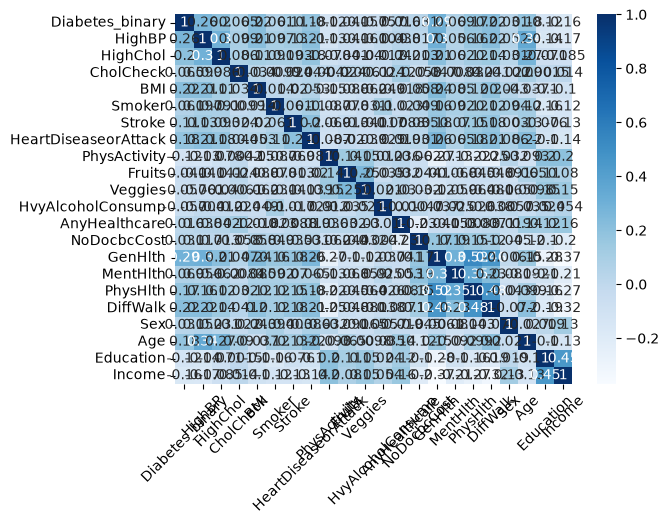

In [10]:
sns.heatmap(df.corr(), annot=True, cmap='Blues')
plt.xticks(rotation=45)
plt.show()

In [11]:
X = df.drop('Diabetes_binary', axis=1)
y = df['Diabetes_binary']

In [12]:
RANDOM_STATE = 42

N_SPLITS = 5

outer_cv = StratifiedKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)
groups = None


# Seluruh fold dipakai; setiap baris menjadi validation tepat sekali.
split_summary(X, y, outer_cv, groups)


,Fold,Train,Validation,Positif train,Positif validation
0,1,202944,50736,28277,7069
1,2,202944,50736,28277,7069
2,3,202944,50736,28277,7069
3,4,202944,50736,28277,7069
4,5,202944,50736,28276,7070


In [13]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(ada_params):
    model_params = ada_params.copy()
    max_depth = model_params.pop('max_depth')
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(sampling_strategy='minority', random_state=RANDOM_STATE)),
        ('ada', AdaBoostClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=max_depth, random_state=RANDOM_STATE
            ),
            random_state=RANDOM_STATE,
            **model_params
        ))
    ])

In [14]:
baseline_params = {
    'learning_rate': 0.1,
    'n_estimators': 100,
    'max_depth': 4
}

In [15]:
baseline_pipeline = make_pipeline(baseline_params)
baseline_cv = evaluate_cv(
    make_pipeline, baseline_params, X, y, outer_cv, groups
)


Outer fold 1/5: train=202944, validation=50736
Outer fold 2/5: train=202944, validation=50736
Outer fold 3/5: train=202944, validation=50736
Outer fold 4/5: train=202944, validation=50736
Outer fold 5/5: train=202944, validation=50736


In [16]:
# Prediksi out-of-fold: bukan prediksi pada data latih.
y_pred = baseline_cv['prediction']
y_proba = baseline_cv['probability']


In [17]:
print_cv_metrics(baseline_cv)
print('\nClassification Report (OOF Predictions):')
print(classification_report(y, y_pred, zero_division=0))


Cross-Validation Results (Mean +/- Std):
Accuracy          : 0.7969 +/- 0.0032
Balanced Accuracy : 0.7203 +/- 0.0054
Precision         : 0.3644 +/- 0.0033
Recall            : 0.6140 +/- 0.0163
Specificity       : 0.8266 +/- 0.0061
F1                : 0.4573 +/- 0.0042
ROC-AUC           : 0.8184 +/- 0.0038
PR-AUC            : 0.4034 +/- 0.0073

Classification Report (OOF Predictions):
              precision    recall  f1-score   support

         0.0       0.93      0.83      0.88    218334
         1.0       0.36      0.61      0.46     35346

    accuracy                           0.80    253680
   macro avg       0.65      0.72      0.67    253680
weighted avg       0.85      0.80      0.82    253680



Combined OOF confusion matrix (5 folds): 253680 samples.


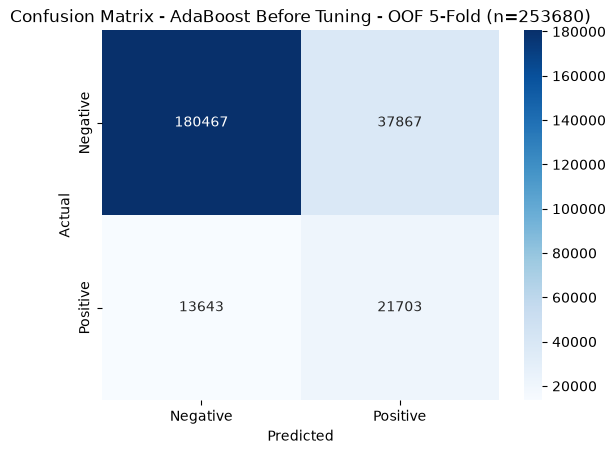

In [18]:
# Confusion matrix gabungan prediksi OOF seluruh outer folds.
# Setiap baris diuji sekali; skor utama tetap mean +/- std antar-fold.
print(f'Combined OOF confusion matrix ({N_SPLITS} folds): {len(y)} samples.')

sns.heatmap(confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'])
plt.title(f'Confusion Matrix - AdaBoost Before Tuning - OOF {N_SPLITS}-Fold (n={len(y)})')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [19]:
def objective(trial, X_train=X, y_train=y, cv=cv, groups_train=groups):
    trial_params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 1.0, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 50, 200, step=50),
        'max_depth': trial.suggest_int('max_depth', 1, 3)
    }
    pipeline = make_pipeline(trial_params)
    with parallel_backend('threading'):
        scores = cross_val_score(
            pipeline, X_train, y_train, cv=cv, scoring='f1', n_jobs=5
        )
    return scores.mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30

# Evaluasi seluruh outer folds; tuning hanya melihat inner training folds.
tuned_cv = nested_cv(
    objective, make_pipeline, X, y, outer_cv, cv,
    n_trials=N_TRIALS, groups=groups, random_state=RANDOM_STATE
)

# Cari parameter model final pada seluruh data setelah evaluasi selesai.
# Model refit ini untuk LIME/deployment, bukan untuk menghitung skor OOF.
study = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=N_TRIALS)


Outer fold 1/5: train=202944, validation=50736
Outer fold 2/5: train=202944, validation=50736
Outer fold 3/5: train=202944, validation=50736
Outer fold 4/5: train=202944, validation=50736
Outer fold 5/5: train=202944, validation=50736


In [20]:
print("Best Params:", study.best_params)
print(f"Best mean CV F1: {study.best_value:.4f}")

# Simpan hasil tuning agar otomatis digunakan notebook perbandingan.
import json
from pathlib import Path

params_path = Path('best_params_brfss.json')
tuning_results = (
    json.loads(params_path.read_text(encoding='utf-8'))
    if params_path.exists() else {}
)
# Simpan prediksi dan metrik outer folds untuk notebook komparasi.
cv_result_file = save_cv_result(
    tuned_cv, X, y, groups,
    Path('cv_results/adaboost_brfss.json.gz'), study.best_params
)
outer_scores = summary_row(tuned_cv)
tuning_results['AdaBoost'] = {
    'params': study.best_params,
    'cv_f1': float(study.best_value),
    'outer_cv_f1': outer_scores['F1'],
    'outer_cv_f1_std': outer_scores['F1 Std'],
    'evaluation_protocol': CV_PROTOCOL,
    'outer_n_splits': N_SPLITS,
    'inner_n_splits': N_SPLITS,
    'cv_result_file': cv_result_file
}
params_path.write_text(
    json.dumps(tuning_results, indent=2), encoding='utf-8'
)
print(f'Best AdaBoost parameters saved to: {params_path.resolve()}')

# Refit pada seluruh data setelah evaluasi; skor tetap dari prediksi OOF.
best_pipeline = make_pipeline(study.best_params)
best_pipeline.fit(X, y)


Best Params: {'learning_rate': 0.14670817273054054, 'n_estimators': 150, 'max_depth': 3}
Best mean CV F1: 0.4575
Best AdaBoost parameters saved to: D:\TELKOM\PENPRO\Diabetes\Model\temp\best_params_brfss.json


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[float64](2,)","[0.,1.]"
feature_names_in_,"ndarray[object](21,)","['HighBP','HighChol','CholCheck',...,'Age','Education','Income']"
n_features_in_,int,21
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None


In [21]:
optuna_prediction = tuned_cv['prediction']
optuna_proba = tuned_cv['probability']

print_cv_metrics(tuned_cv)
print('\nClassification Report (OOF Predictions):')
print(classification_report(y, optuna_prediction, zero_division=0))


Cross-Validation Results (Mean +/- Std):
Accuracy          : 0.7976 +/- 0.0139
Balanced Accuracy : 0.7176 +/- 0.0085
Precision         : 0.3654 +/- 0.0156
Recall            : 0.6066 +/- 0.0385
Specificity       : 0.8285 +/- 0.0223
F1                : 0.4551 +/- 0.0042
ROC-AUC           : 0.8188 +/- 0.0030
PR-AUC            : 0.4045 +/- 0.0052

Classification Report (OOF Predictions):
              precision    recall  f1-score   support

         0.0       0.93      0.83      0.88    218334
         1.0       0.36      0.61      0.46     35346

    accuracy                           0.80    253680
   macro avg       0.65      0.72      0.67    253680
weighted avg       0.85      0.80      0.82    253680



In [22]:
baseline_scores = summary_row(baseline_cv)
tuned_scores = summary_row(tuned_cv)

for metric in ['Accuracy', 'F1']:
    print(f"Baseline {metric}: {baseline_scores[metric]:.4f} +/- "
          f"{baseline_scores[f'{metric} Std']:.4f}")
    print(f"Tuned {metric}   : {tuned_scores[metric]:.4f} +/- "
          f"{tuned_scores[f'{metric} Std']:.4f}")


Baseline Accuracy: 0.7969 +/- 0.0032
Tuned Accuracy   : 0.7976 +/- 0.0139
Baseline F1: 0.4573 +/- 0.0042
Tuned F1   : 0.4551 +/- 0.0042


Combined OOF confusion matrix (5 folds): 253680 samples.


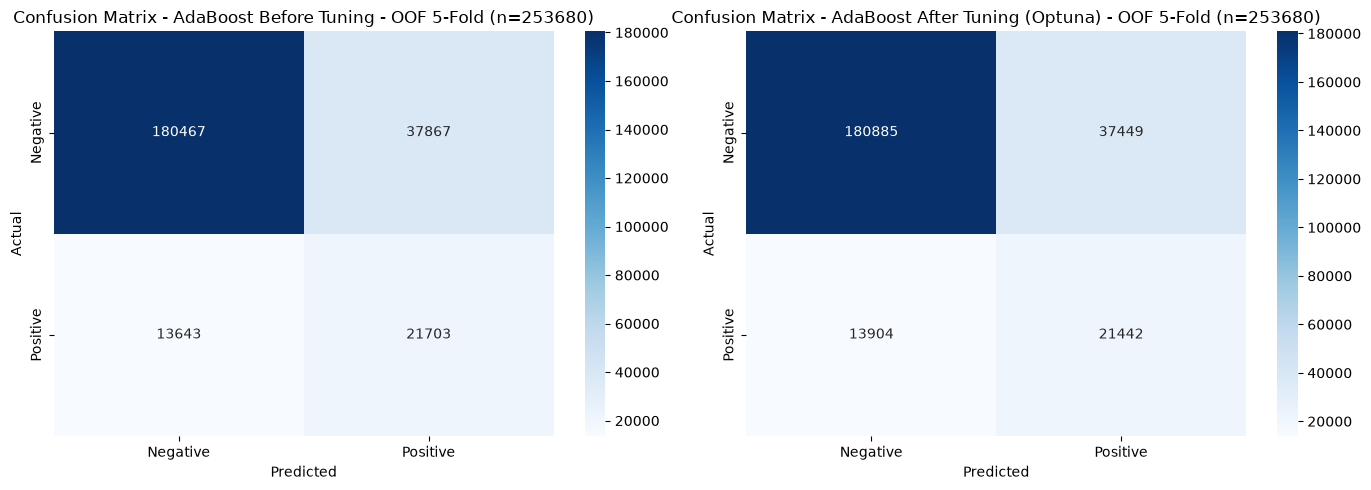

In [23]:
# Confusion matrix gabungan prediksi OOF seluruh outer folds.
# Setiap baris diuji sekali; skor utama tetap mean +/- std antar-fold.
assert np.array_equal(baseline_cv['fold_id'], tuned_cv['fold_id']), \
    'Fold baseline dan tuning harus identik.'
print(f'Combined OOF confusion matrix ({N_SPLITS} folds): {len(y)} samples.')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'], ax=ax[0])
ax[0].set_title(f"Confusion Matrix - AdaBoost Before Tuning - OOF {N_SPLITS}-Fold (n={len(y)})")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")


sns.heatmap(confusion_matrix(y, optuna_prediction), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'], ax=ax[1])
ax[1].set_title(f"Confusion Matrix - AdaBoost After Tuning (Optuna) - OOF {N_SPLITS}-Fold (n={len(y)})")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [24]:
# Variasi antar-fold; bukan bootstrap test set atau confidence interval.
fold_scores = tuned_cv['folds']['Accuracy'].to_numpy()
mean_acc = fold_scores.mean()
std_acc = fold_scores.std(ddof=1)

print(f'Mean Accuracy ({N_SPLITS}-Fold CV): {mean_acc:.4f} +/- {std_acc:.4f}')
tuned_cv['folds'].drop(columns='Best Params').round(4)


Mean Accuracy (5-Fold CV): 0.7976 +/- 0.0139


,Fold,Train Rows,Validation Rows,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,Fit seconds,Inner CV F1
0,1,202944,50736,0.8081,0.7155,0.3783,0.5871,0.8438,0.4601,0.8231,0.4092,3362.1897,0.4559
1,2,202944,50736,0.8018,0.7101,0.3669,0.5830,0.8372,0.4504,0.8174,0.3964,3808.1595,0.4575
2,3,202944,50736,0.7788,0.7308,0.3467,0.6643,0.7974,0.4556,0.8191,0.4039,3675.3579,0.4566
3,4,202944,50736,0.8117,0.7111,0.3823,0.5717,0.8505,0.4582,0.8194,0.4087,3264.8432,0.4564
4,5,202944,50736,0.7875,0.7203,0.3525,0.6272,0.8135,0.4514,0.8150,0.4044,3006.4518,0.4578


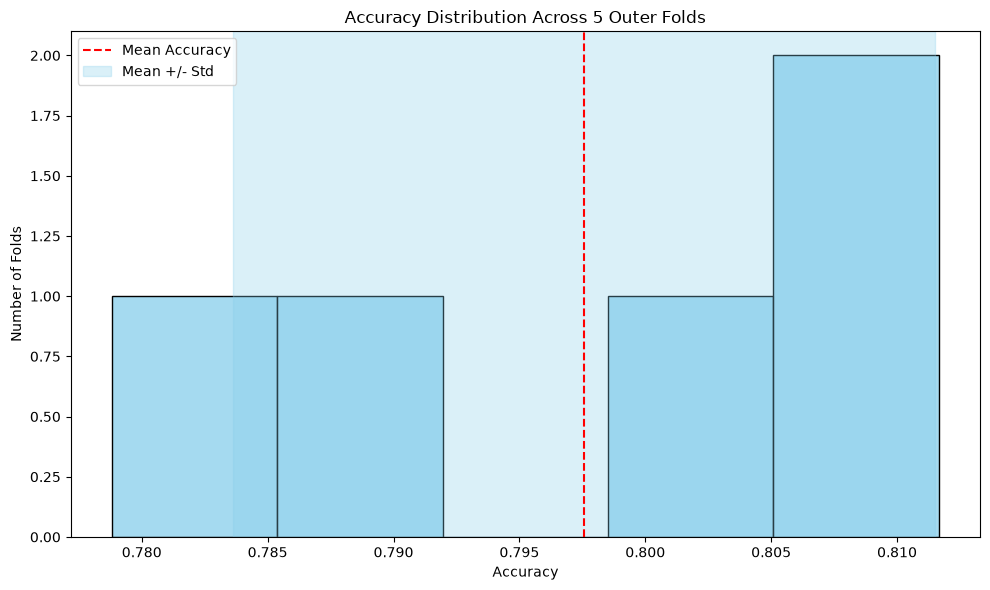

In [25]:
plt.figure(figsize=(10, 6))
sns.histplot(fold_scores, bins=N_SPLITS, color='skyblue')
plt.axvline(mean_acc, color='red', linestyle='--', label='Mean Accuracy')
plt.axvspan(mean_acc - std_acc, mean_acc + std_acc,
            color='skyblue', alpha=0.3, label='Mean +/- Std')
plt.title(f'Accuracy Distribution Across {N_SPLITS} Outer Folds')
plt.xlabel('Accuracy')
plt.ylabel('Number of Folds')
plt.legend()
plt.tight_layout()
plt.show()


In [26]:
from lime.lime_tabular import LimeTabularExplainer
import random

In [27]:
# LIME menggunakan model final yang sudah direfit pada seluruh data.
X_imputed = pd.DataFrame(
    best_pipeline.named_steps['imputer'].transform(X),
    columns=X.columns, index=X.index
)

explainer = LimeTabularExplainer(
    training_data=X_imputed.values,
    feature_names=X.columns.tolist(),
    class_names=['Negative', 'Positive'],
    mode='classification',
    random_state=RANDOM_STATE
)

In [28]:
rng_lime = np.random.default_rng(RANDOM_STATE)
sample_index = int(rng_lime.integers(0, len(X)))
sample_data = X.iloc[sample_index]
sample_data_imputed = best_pipeline.named_steps['imputer'].transform(
    sample_data.to_frame().T
)[0]

def lime_predict(data):
    data_df = pd.DataFrame(data, columns=X.columns)
    return best_pipeline.predict_proba(data_df)

exp = explainer.explain_instance(
    data_row=sample_data_imputed,
    predict_fn=lime_predict,
    num_features=5
)

In [29]:
from IPython.display import HTML, display

html_output = exp.as_html(show_table=True, show_all=False)
actual_label = 'Positive' if y.iloc[sample_index] == 1 else 'Negative'
print(f'Actual value for sample index {sample_index}: {actual_label}')
display(HTML(html_output))


Actual value for sample index 22641: Negative


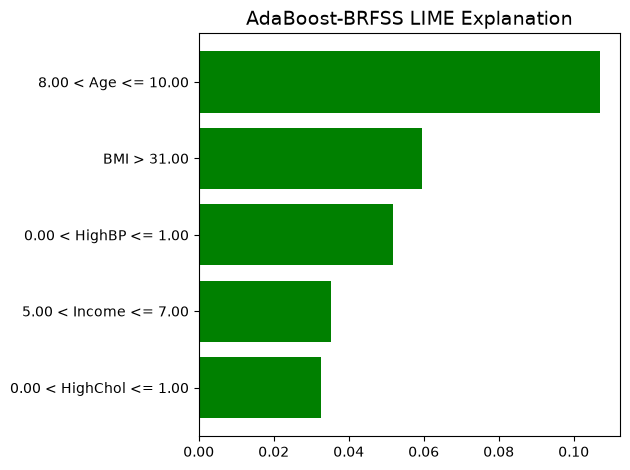

LIME image saved to: D:\TELKOM\PENPRO\Diabetes\Model\temp\lime_adaboost_brfss.png


In [30]:
from pathlib import Path

output_path = Path('lime_adaboost_brfss.png')

label = exp.available_labels()[0]
fig = exp.as_pyplot_figure(label=label)
fig.axes[0].set_title('AdaBoost-BRFSS LIME Explanation', fontsize=14)

fig.tight_layout()
fig.savefig(
    output_path,
    format='png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
print(f'LIME image saved to: {output_path.resolve()}')
